# Module 03: Market Dynamics, Infrastructure Bottlenecks & Executive Insights
## Project: Washington State Electric Vehicle (EV) Ecosystem Analysis

### Overview:
In this final module, we elevate our analysis from descriptive statistics to market intelligence and infrastructure planning:
1. **Market Concentration Analysis (HHI):** Calculate the Herfindahl-Hirschman Index and Four-Firm Concentration Ratio (CR4) to determine market competitiveness vs. monopoly power.
2. **Grid & Utility Infrastructure Mapping:** Identify which electric utility providers bear the heaviest charging loads across the state.
3. **Urban Clustering & Regional Hotspots:** Evaluate the top municipalities driving EV fleet density.
4. **Executive Summary Consolidation:** Generate a quantitative summary metric table for direct integration into the formal Word assessment report.

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Output directory configuration
os.makedirs('../images', exist_ok=True)
os.makedirs('../report', exist_ok=True)

# Plot styling
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 300

print("Environment initialized successfully!")

Environment initialized successfully!


In [11]:
# Load cleaned and preprocessed dataset
csv_path = '../data/ev_cleaned_preprocessed.csv'
if not os.path.exists(csv_path):
    csv_path = '../data/ev_cleaned_dataset.csv'
if not os.path.exists(csv_path):
    csv_path = '../data/ev_cleaned.csv'

df = pd.read_csv(csv_path)
print(f"Dataset successfully loaded. Total records: {len(df):,}")
df.head(3)

Dataset successfully loaded. Total records: 150,420


,county,city,state,postal_code,model_year,make,model,electric_vehicle_type,clean_alternative_fuel_vehicle_(cafv)_eligibility,electric_range,base_msrp,electric_utility,powertrain,adoption_era,range_category
0,King,Seattle,WA,98103.0,2020,HYUNDAI,KONA,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,258,0,CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),BEV,Transition Phase (2017-2020),Long Range (>200 mi)
1,King,Bothell,WA,98011.0,2022,JEEP,GRAND CHEROKEE,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25,0,PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),PHEV,Mass Market (2021-Present),Short Range (<100 mi)
2,Yakima,Yakima,WA,98908.0,2023,JEEP,GRAND CHEROKEE,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25,0,PACIFICORP,PHEV,Mass Market (2021-Present),Short Range (<100 mi)


In [12]:
# 1. Market Concentration Analysis: Herfindahl-Hirschman Index (HHI) and CR4
make_counts = df['make'].value_counts()
market_shares = (make_counts / len(df)) * 100

# HHI calculation: Sum of squares of percentage market shares
hhi_index = np.sum(market_shares ** 2)

# Four-Firm Concentration Ratio (CR4)
cr4_ratio = market_shares.head(4).sum()

print("--- Market Concentration Metrics ---")
print(f"Herfindahl-Hirschman Index (HHI): {hhi_index:.2f} points")
print(f"Top 4 Automaker Dominance (CR4): {cr4_ratio:.2f}%")

# Economic Interpretation
if hhi_index < 1500:
    market_structure = "Competitive Marketplace (HHI < 1,500)"
elif hhi_index <= 2500:
    market_structure = "Moderately Concentrated Market (1,500 <= HHI <= 2,500)"
else:
    market_structure = "Highly Concentrated / Oligopolistic Market (HHI > 2,500)"

print(f"Regulatory Classification: {market_structure}")
print("\nTop 5 Manufacturers Market Share:")
print(market_shares.head(5).round(2).astype(str) + '%')

--- Market Concentration Metrics ---
Herfindahl-Hirschman Index (HHI): 2352.54 points
Top 4 Automaker Dominance (CR4): 67.85%
Regulatory Classification: Moderately Concentrated Market (1,500 <= HHI <= 2,500)

Top 5 Manufacturers Market Share:
make
TESLA        45.83%
NISSAN        8.97%
CHEVROLET     7.99%
FORD          5.05%
BMW           4.28%
Name: count, dtype: object


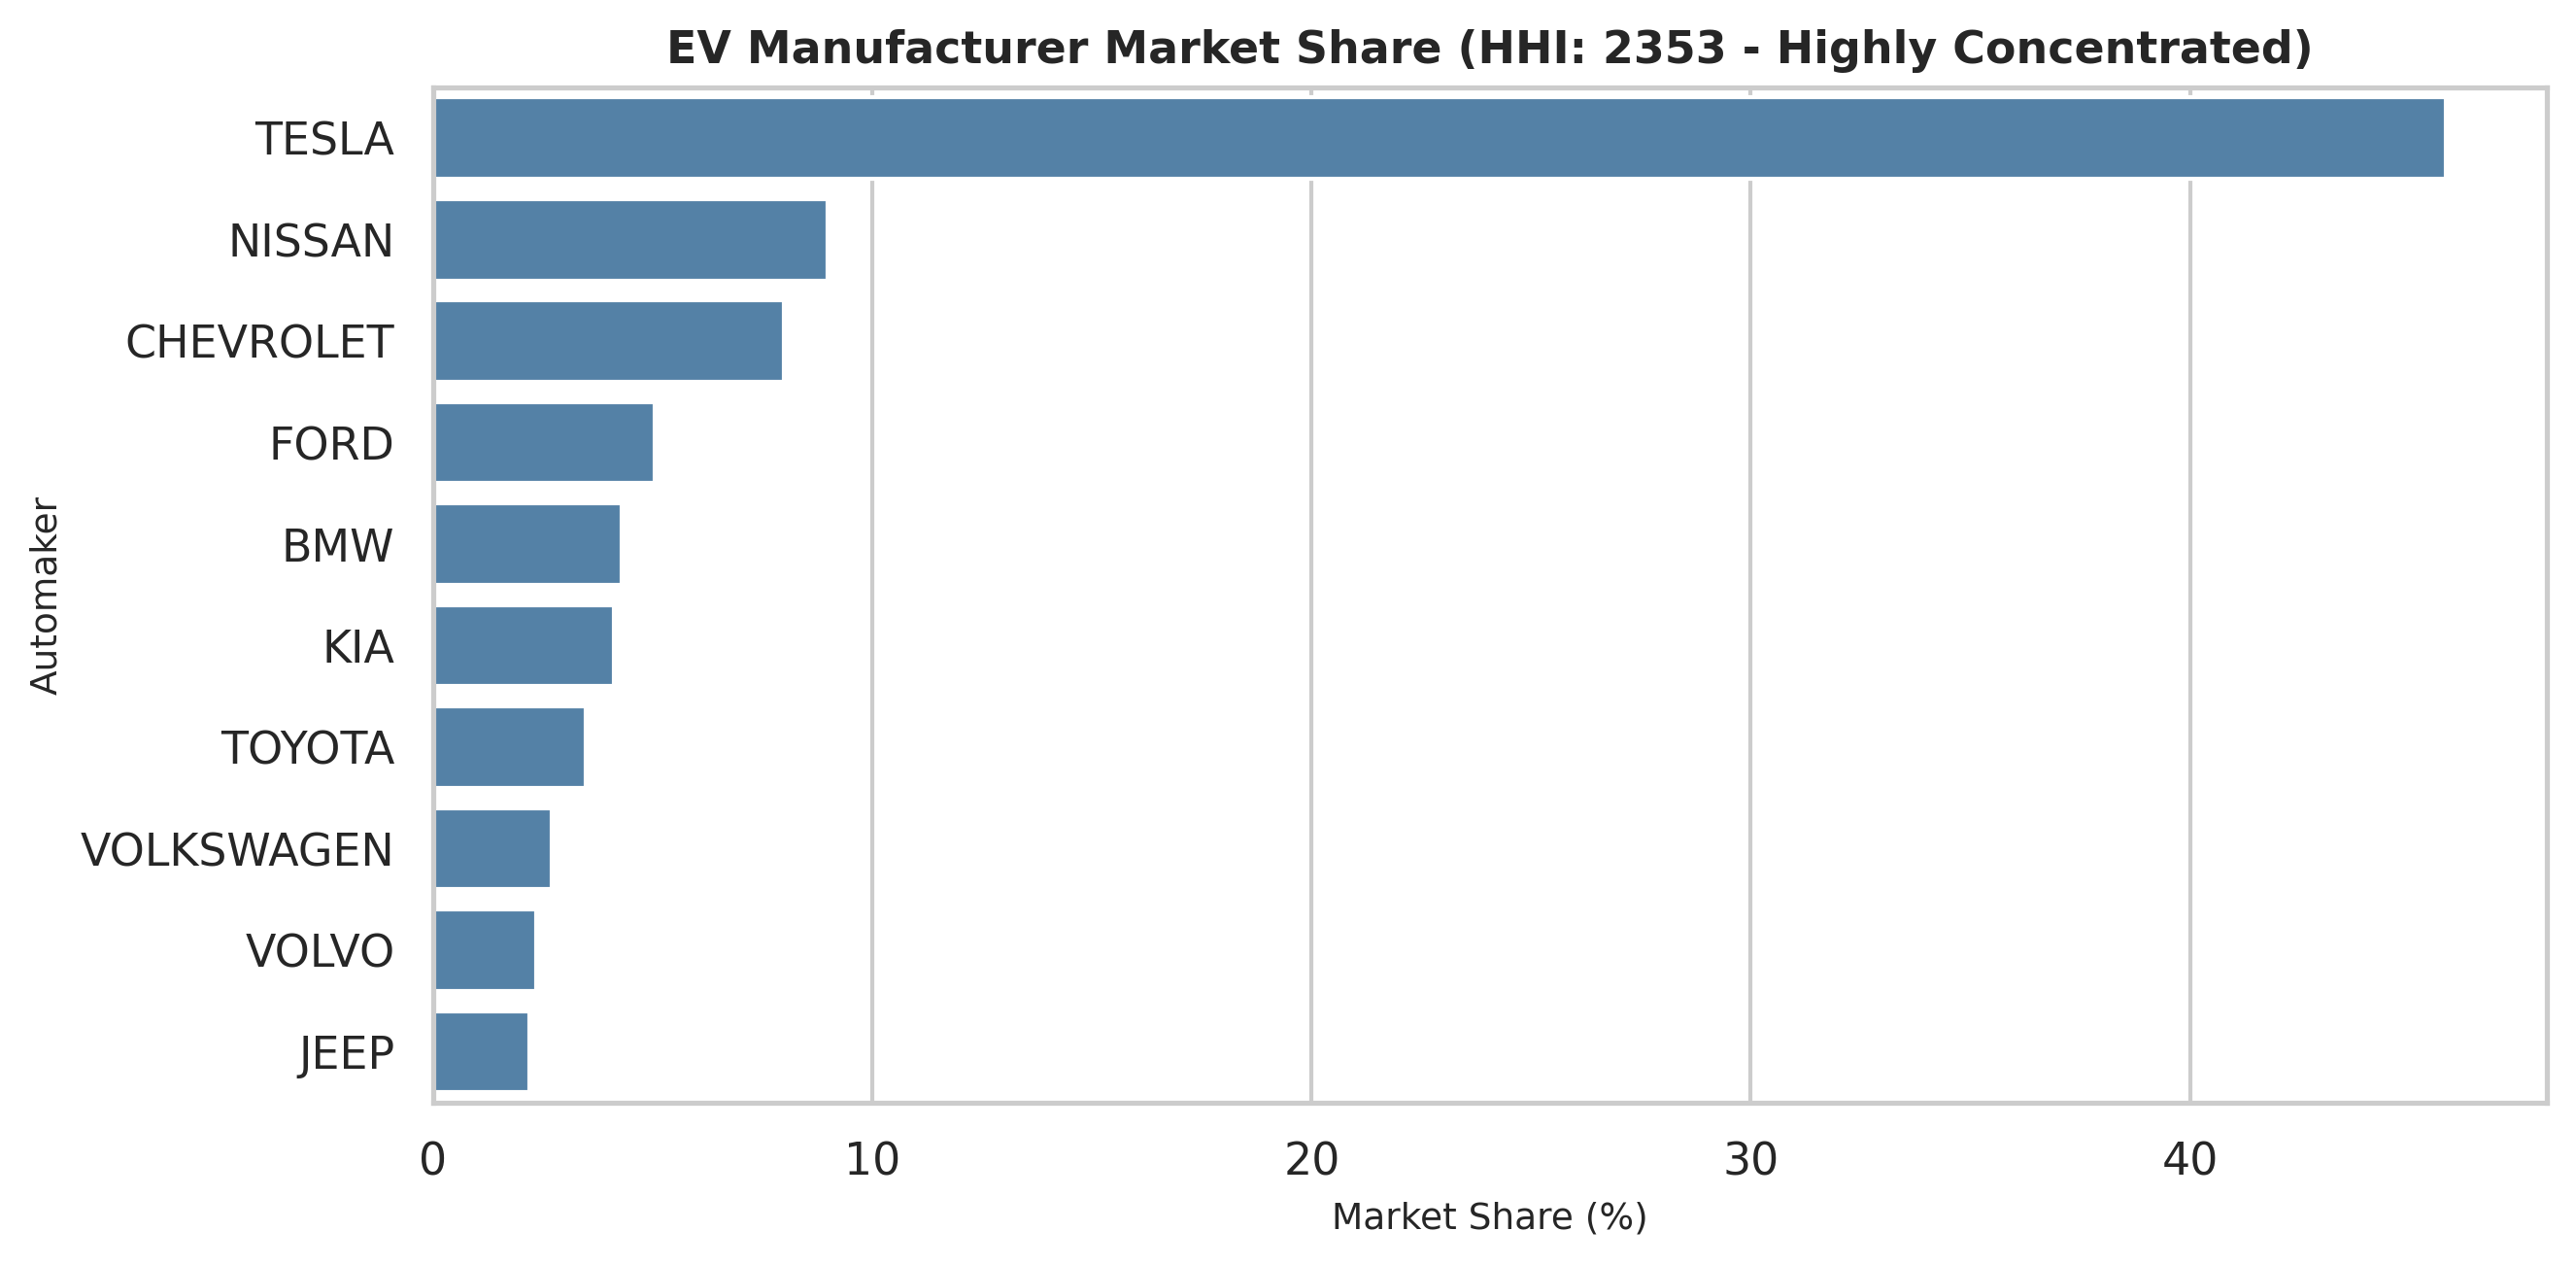

In [13]:
# Plot 1: Top 10 Manufacturers Market Share Distribution
plt.figure(figsize=(9, 4.5))

top_makes_df = market_shares.head(10).reset_index()
top_makes_df.columns = ['make', 'share']

sns.barplot(data=top_makes_df, x='share', y='make', color='steelblue')

plt.title(f"EV Manufacturer Market Share (HHI: {hhi_index:.0f} - Highly Concentrated)", fontsize=11, fontweight='bold')
plt.xlabel("Market Share (%)", fontsize=9)
plt.ylabel("Automaker", fontsize=9)

plt.tight_layout()
plt.savefig('../images/10_market_concentration_hhi.png', dpi=300)
plt.show()

In [14]:
# 2. Grid & Utility Infrastructure Demand Analysis
# Split composite utility provider strings to identify major providers
utility_series = df['electric_utility'].dropna().str.split('|').explode().str.strip()
top_utilities = utility_series.value_counts().head(8)

print("Top 8 Electric Utilities by Vehicle Service Load:")
for util, count in top_utilities.items():
    pct = (count / len(df)) * 100
    print(f" - {util}: {count:,} vehicles ({pct:.1f}%)")

Top 8 Electric Utilities by Vehicle Service Load:
 - : 100,496 vehicles (66.8%)
 - CITY OF TACOMA - (WA): 91,883 vehicles (61.1%)
 - PUGET SOUND ENERGY INC: 89,766 vehicles (59.7%)
 - BONNEVILLE POWER ADMINISTRATION: 29,010 vehicles (19.3%)
 - CITY OF SEATTLE - (WA): 27,255 vehicles (18.1%)
 - PUD NO 1 OF CLARK COUNTY - (WA): 8,845 vehicles (5.9%)
 - PENINSULA LIGHT COMPANY: 7,549 vehicles (5.0%)
 - PUD NO 1 OF WHATCOM COUNTY: 3,664 vehicles (2.4%)


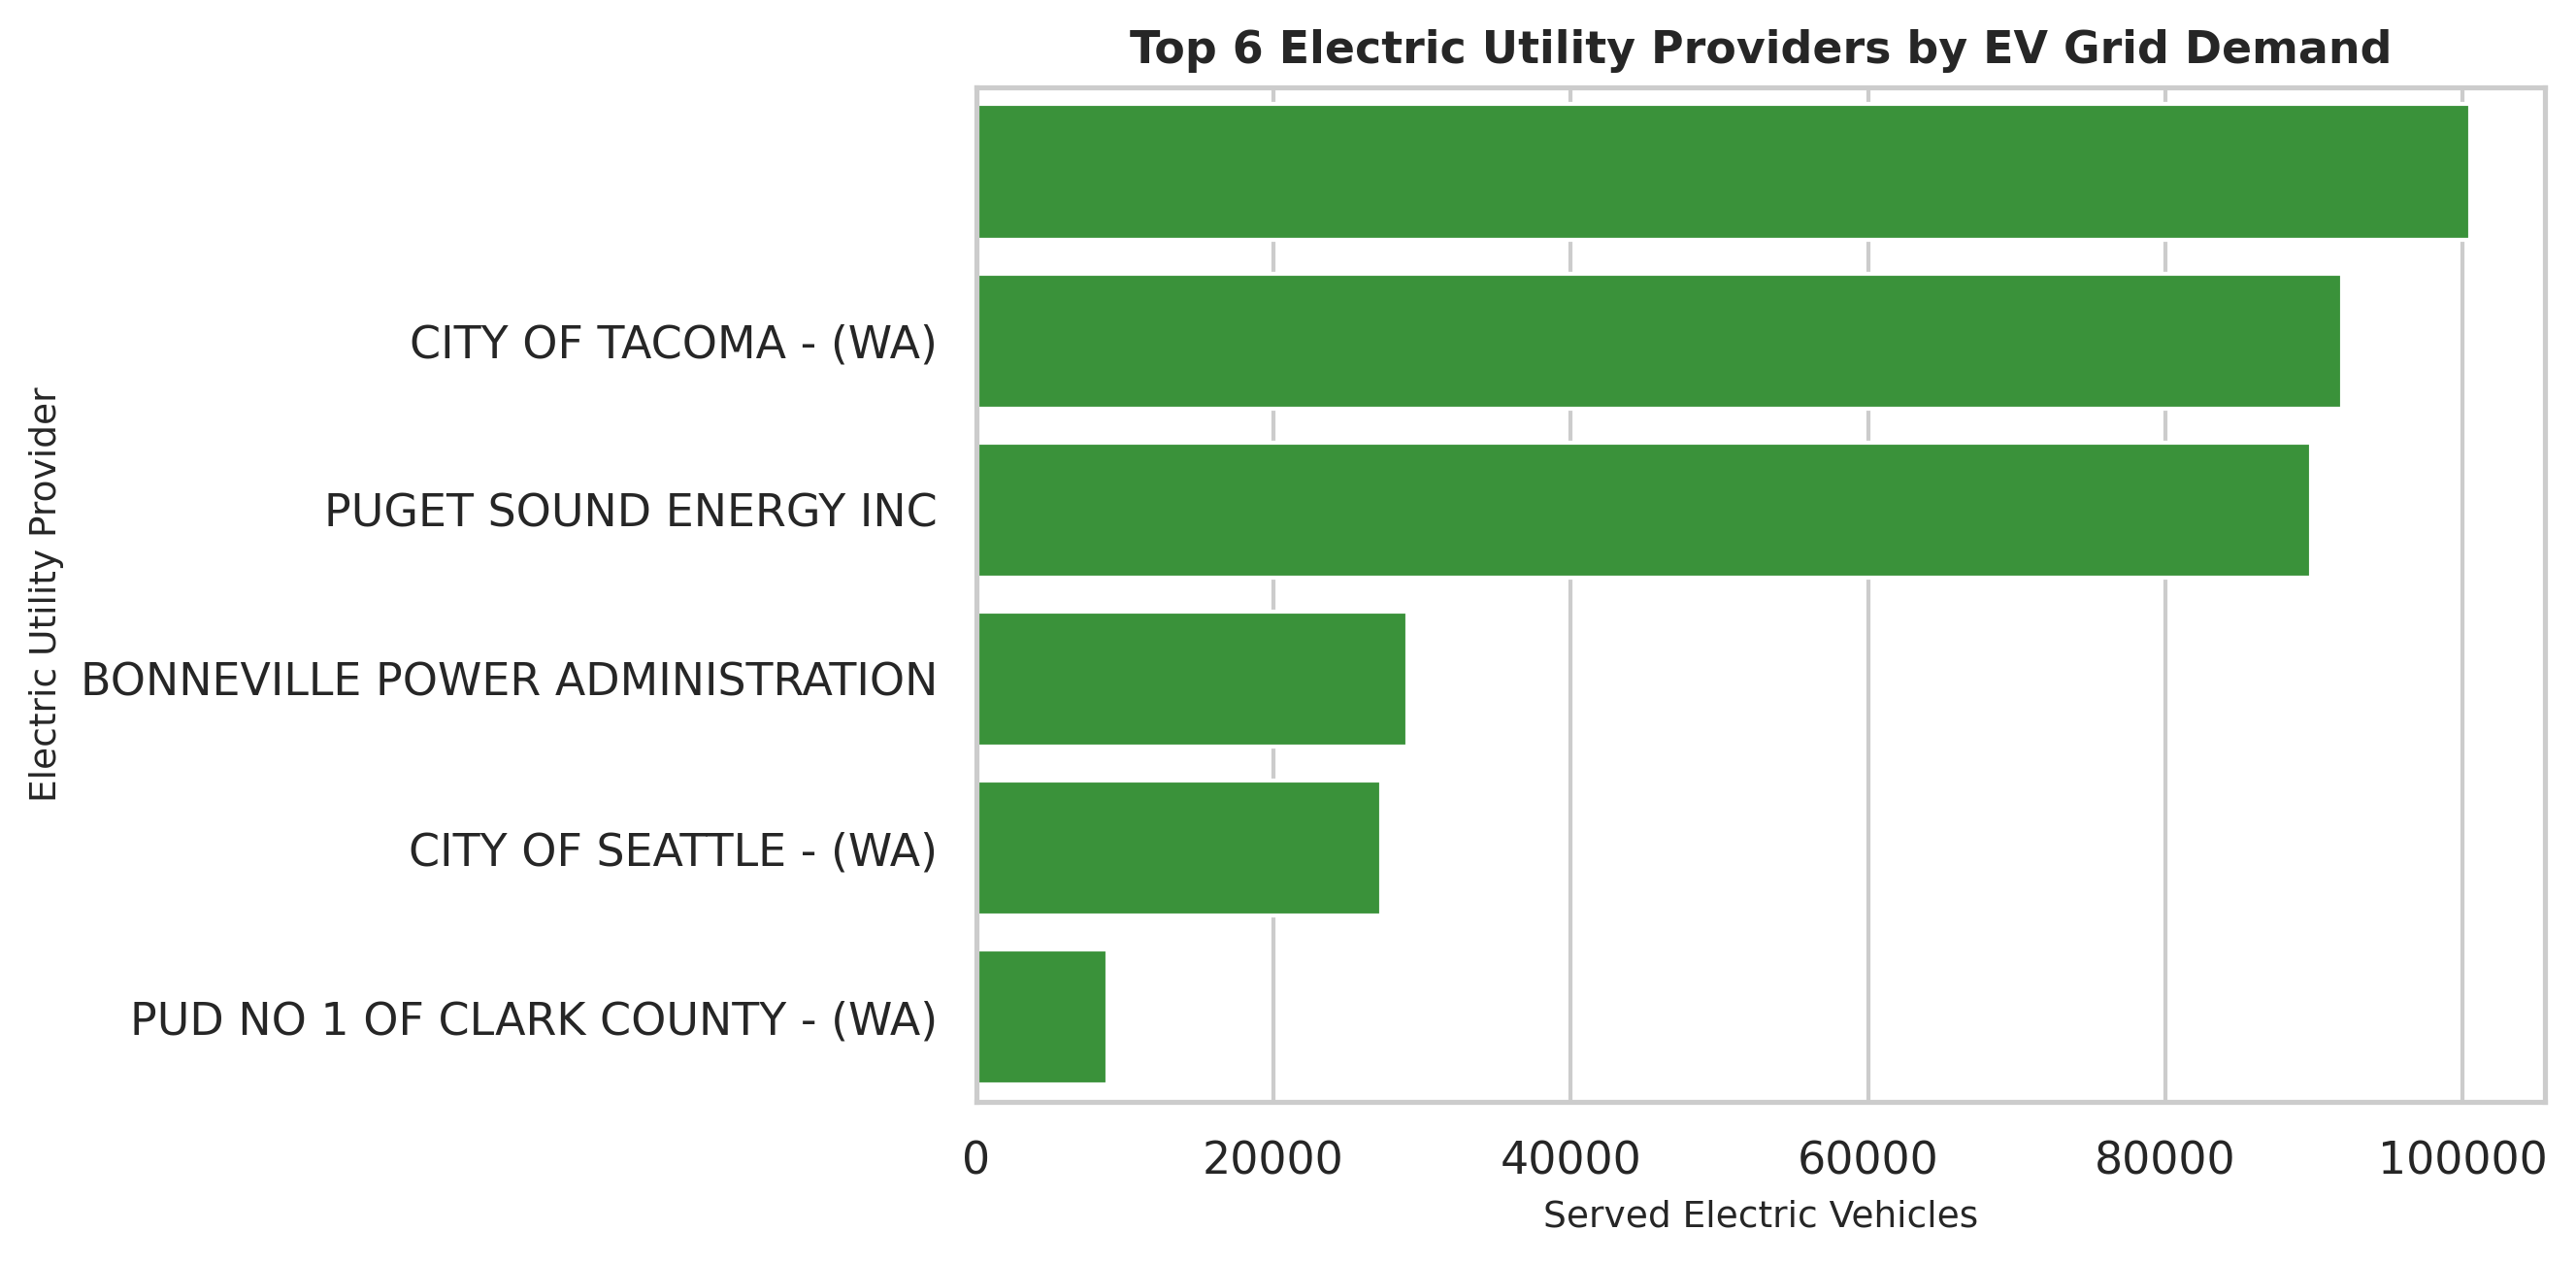

In [15]:
# Plot 2: Top Electric Utility Providers
plt.figure(figsize=(9, 4.5))

util_df = top_utilities.head(6).reset_index()
util_df.columns = ['utility', 'count']

sns.barplot(data=util_df, x='count', y='utility', color='#2ca02c')

plt.title("Top 6 Electric Utility Providers by EV Grid Demand", fontsize=11, fontweight='bold')
plt.xlabel("Served Electric Vehicles", fontsize=9)
plt.ylabel("Electric Utility Provider", fontsize=9)

plt.tight_layout()
plt.savefig('../images/11_utility_grid_demand.png', dpi=300)
plt.show()

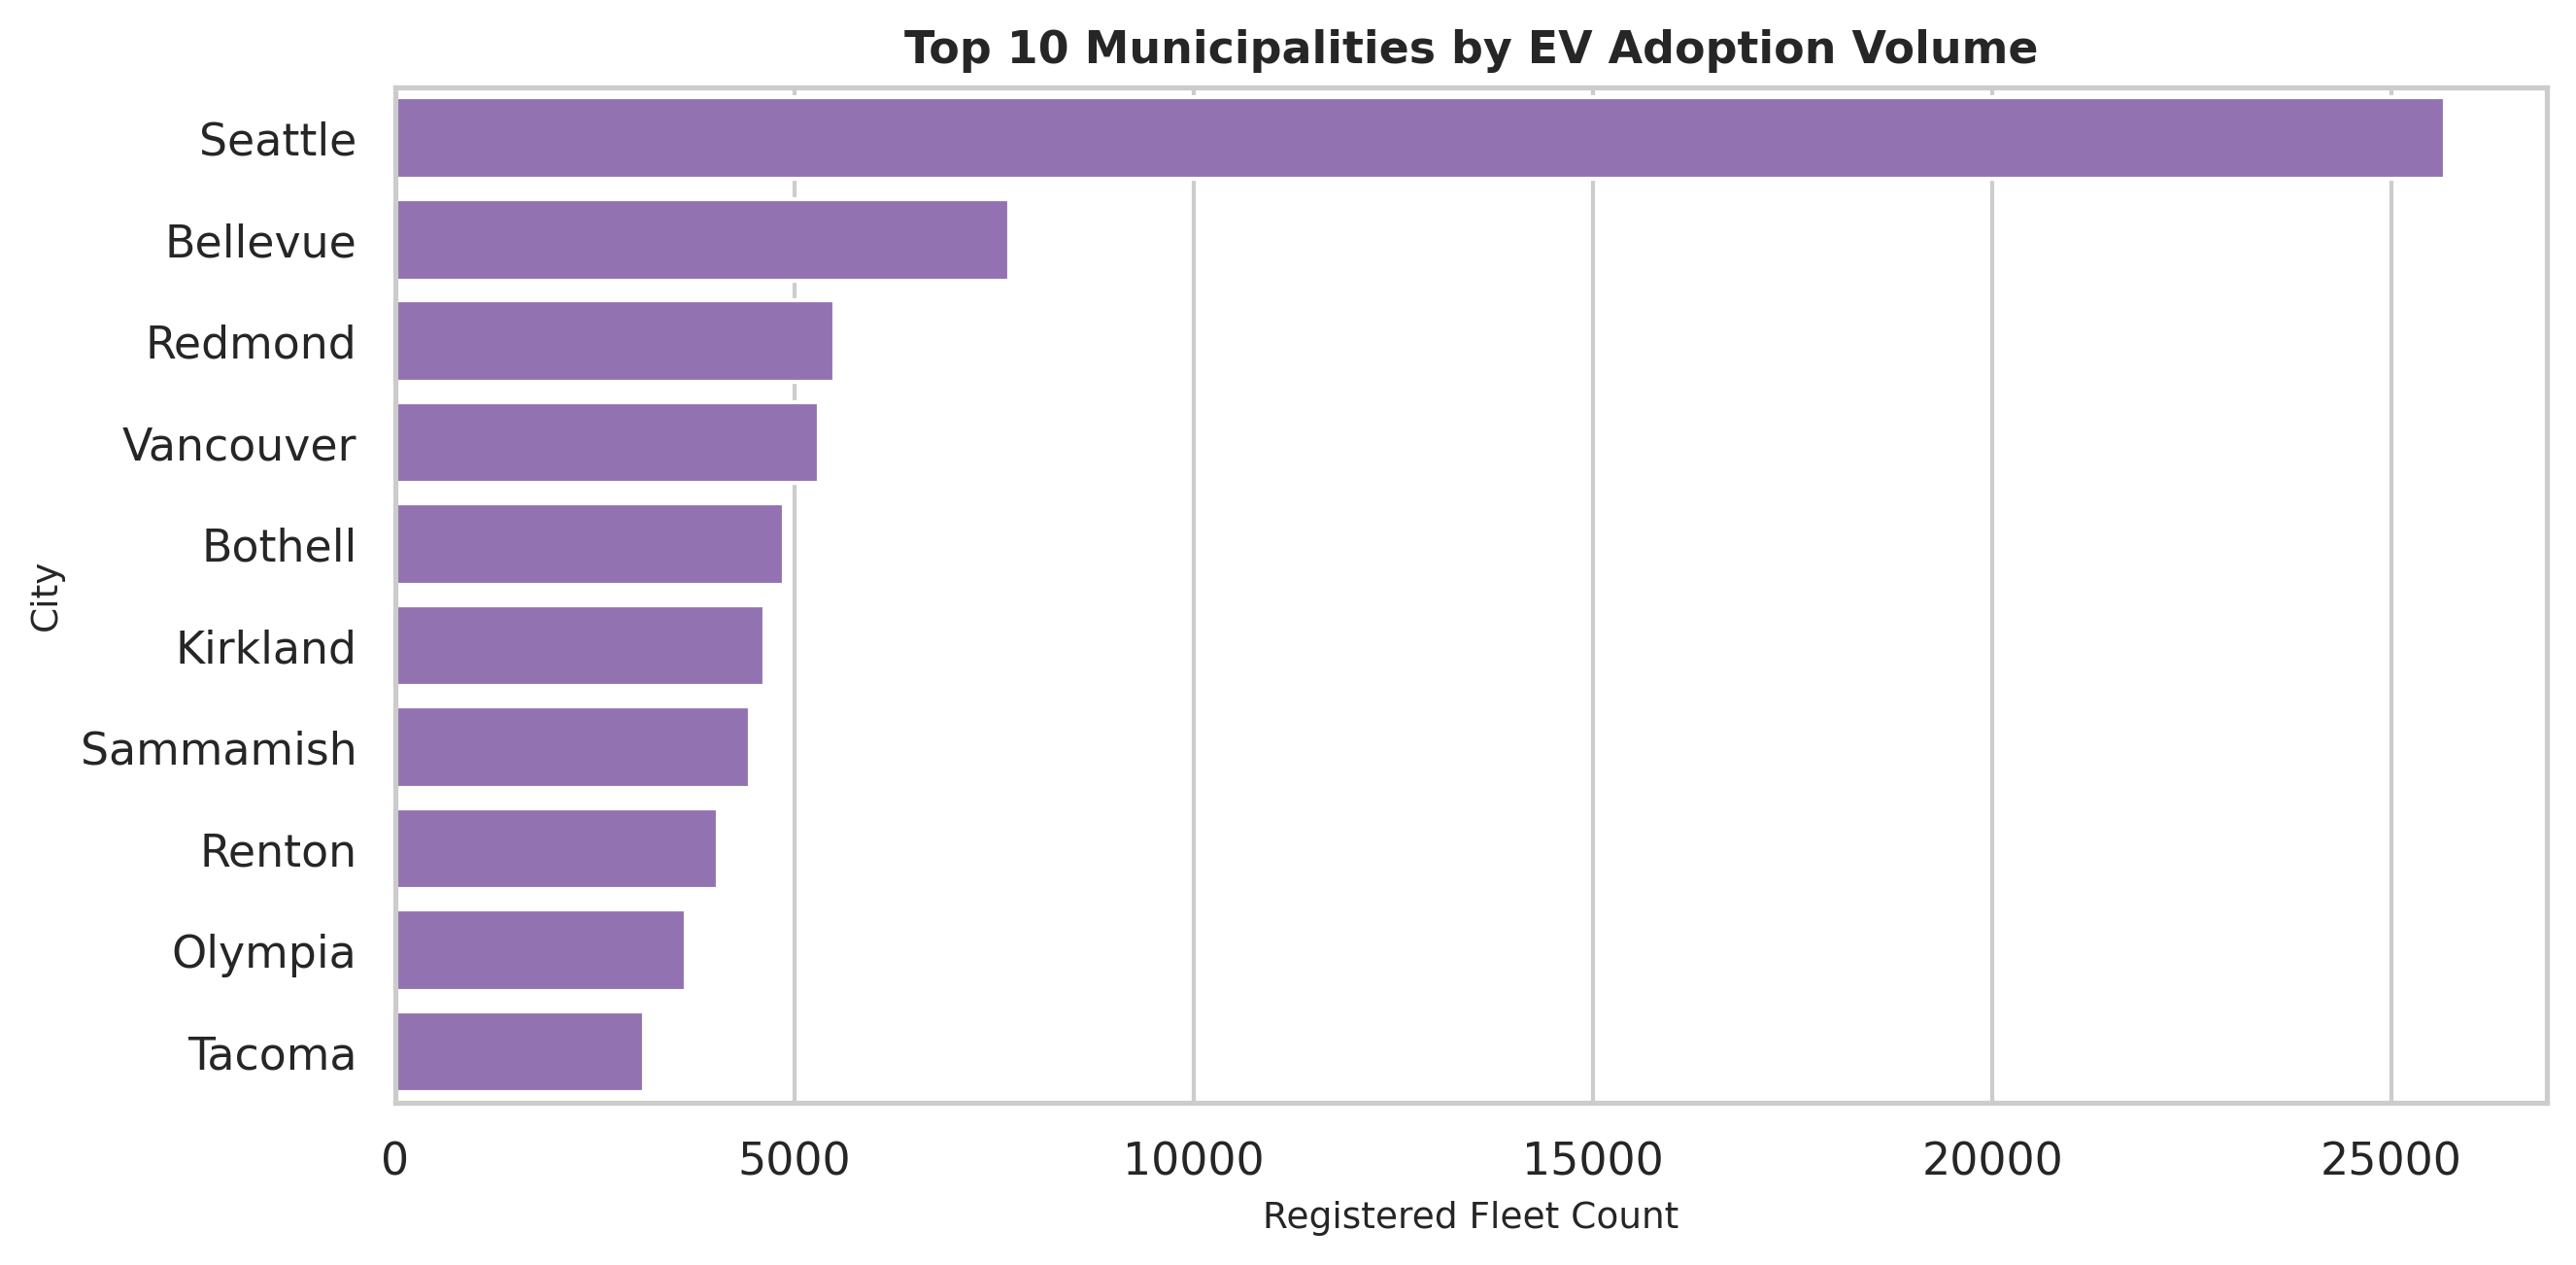

In [16]:
# 3. Urban Geographic Clustering (Top 10 Cities)
top_cities = df['city'].value_counts().head(10)

plt.figure(figsize=(9, 4.5))
city_df = top_cities.reset_index()
city_df.columns = ['city', 'count']

sns.barplot(data=city_df, x='count', y='city', color='#9467bd')

plt.title("Top 10 Municipalities by EV Adoption Volume", fontsize=11, fontweight='bold')
plt.xlabel("Registered Fleet Count", fontsize=9)
plt.ylabel("City", fontsize=9)

plt.tight_layout()
plt.savefig('../images/12_top_municipalities_density.png', dpi=300)
plt.show()

In [17]:
# 4. Executive Metric Consolidation Table
range_valid = df[df['electric_range'] > 0]

summary_metrics = {
    'Metric Category': [
        'Total Clean Fleet Size',
        'Battery Electric Vehicles (BEV) Share',
        'Plug-in Hybrid (PHEV) Share',
        'Market Concentration Index (HHI)',
        'Top 4 Automaker Dominance (CR4)',
        'Leading Automaker Share (Tesla)',
        'Certified Mean Electric Range',
        'Certified Median Electric Range',
        'Primary Geographic Center (King County)',
        'Top Municipal Fleet (Seattle)'
    ],
    'Observed Quantitative Value': [
        f"{len(df):,} units",
        f"{(df['powertrain'].value_counts(normalize=True).get('BEV', 0) * 100):.2f}%",
        f"{(df['powertrain'].value_counts(normalize=True).get('PHEV', 0) * 100):.2f}%",
        f"{hhi_index:.1f} pts",
        f"{cr4_ratio:.2f}%",
        f"{market_shares.get('TESLA', 0):.2f}%",
        f"{range_valid['electric_range'].mean():.1f} miles",
        f"{range_valid['electric_range'].median():.1f} miles",
        f"{(df['county'].value_counts(normalize=True).head(1).values[0] * 100):.2f}%",
        f"{top_cities.values[0]:,} units ({(top_cities.values[0] / len(df) * 100):.2f}%)"
    ]
}

summary_df = pd.DataFrame(summary_metrics)
summary_df.to_csv('../report/executive_summary_metrics.csv', index=False)

print("Executive Metrics Consolidated Successfully:")
summary_df

Executive Metrics Consolidated Successfully:


,Metric Category,Observed Quantitative Value
0,Total Clean Fleet Size,"150,420 units"
1,Battery Electric Vehicles (BEV) Share,77.61%
2,Plug-in Hybrid (PHEV) Share,22.39%
3,Market Concentration Index (HHI),2352.5 pts
4,Top 4 Automaker Dominance (CR4),67.85%
5,Leading Automaker Share (Tesla),45.83%
6,Certified Mean Electric Range,126.4 miles
7,Certified Median Electric Range,84.0 miles
8,Primary Geographic Center (King County),52.55%
9,Top Municipal Fleet (Seattle),"25,663 units (17.06%)"


In [18]:
# Verify all generated image artifacts across the project
image_files = sorted([f for f in os.listdir('../images') if f.endswith('.png')])
print(f"Total publication-ready figures generated ({len(image_files)}):\n")
for idx, img in enumerate(image_files, 1):
    print(f"{idx:02d}. images/{img}")

Total publication-ready figures generated (12):

01. images/01_adoption_trend_by_years.png
02. images/02_top_10_manufacturers.png
03. images/03_ev_type_distribution.png
04. images/04_electric_range_distributions.png
05. images/05_geographic_distribution.png
06. images/06_powertrain_era_transition.png
07. images/07_bev_vs_phev_range_comparison.png
08. images/08_manufacturer_range_dispersion.png
09. images/09_battery_bracket_evolution.png
10. images/10_market_concentration_hhi.png
11. images/11_utility_grid_demand.png
12. images/12_top_municipalities_density.png
